In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from sklearn.model_selection import train_test_split

# 1. Load dataset (grayscale, resize)

In [ ]:
UKURAN = 224
data_path = "Dataset"
kelas = sorted(os.listdir(data_path))
print(kelas)

x, y = [], []
for label, nama_kelas in enumerate(kelas):
    folder = os.path.join(data_path, nama_kelas)
    print(folder)

    for nama_file in os.listdir(folder):
        if nama_file.endswith("Thumbs.db"):
            continue
        gambar = keras.utils.load_img(os.path.join(folder, nama_file), color_mode="grayscale", target_size=(UKURAN, UKURAN))
        x.append(np.array(gambar))
        y.append(label)

x = np.array(x)
y = np.array(y)

['Broccoli', 'Carrot', 'Cucumber', 'Tomato']
Dataset\Broccoli
Dataset\Carrot
Dataset\Cucumber
Dataset\Tomato


# 2. Preprocessing (normalisasi + one hot encoding)

In [4]:
x = x.astype("float32") / 255.0
y = keras.utils.to_categorical(y, num_classes=len(kelas))

print(x.shape)
print(y.shape)
print(y[0])

(2000, 224, 224)
(2000, 4)
[1. 0. 0. 0.]


# 3. Data split 80 10 10 

In [5]:
# 80 train, 20 temp
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42)

# 20 temp -> 10 val, 10 test
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

print("Train:", len(x_train))
print("Validation:", len(x_val))
print("Test:", len(x_test))

Train: 1600
Validation: 200
Test: 200


# 4. Model DCNN

In [6]:
model = keras.Sequential([
    # input layer
    keras.layers.Input(shape=(UKURAN, UKURAN, 1)),

    # hidden layer
    keras.layers.Conv2D(32, (3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),

    keras.layers.Conv2D(64, (3,3), activation="relu"),
    keras.layers.Conv2D(64, (3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),

    keras.layers.Flatten(),

    # output layer
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(len(kelas), activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 107, 107, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 53, 53, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 179776)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,011,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,075,716 (88.03 MB)

 Trainable params: 23,075,716 (88.03 MB)

 Non-trainable params: 0 (0.00 B)

# 5. Training

In [8]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=32, epochs=10, validation_data=(x_val, y_val))

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 48s 929ms/step - accuracy: 0.3856 - loss: 1.3469 - val_accuracy: 0.7200 - val_loss: 0.8697
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 46s 927ms/step - accuracy: 0.7181 - loss: 0.7173 - val_accuracy: 0.8550 - val_loss: 0.4175
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 81s 892ms/step - accuracy: 0.8081 - loss: 0.5256 - val_accuracy: 0.8750 - val_loss: 0.3015
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 47s 932ms/step - accuracy: 0.8687 - loss: 0.3802 - val_accuracy: 0.8750 - val_loss: 0.3300
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 46s 926ms/step - accuracy: 0.8788 - loss: 0.3415 - val_accuracy: 0.9100 - val_loss: 0.2397
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 47s 936ms/step - accuracy: 0.9031 - loss: 0.2628 - val_accuracy: 0.9050 - val_loss: 0.3251
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 45s 908ms/step - accuracy: 0.9381 - loss: 0.1792 - val_accuracy: 0.8850 - val_loss: 0.2538
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 43s 870ms/step - accuracy: 0.9381 - loss: 0.1821 - val_accu

# 6. Show Prediction (9 gambar test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 209ms/step


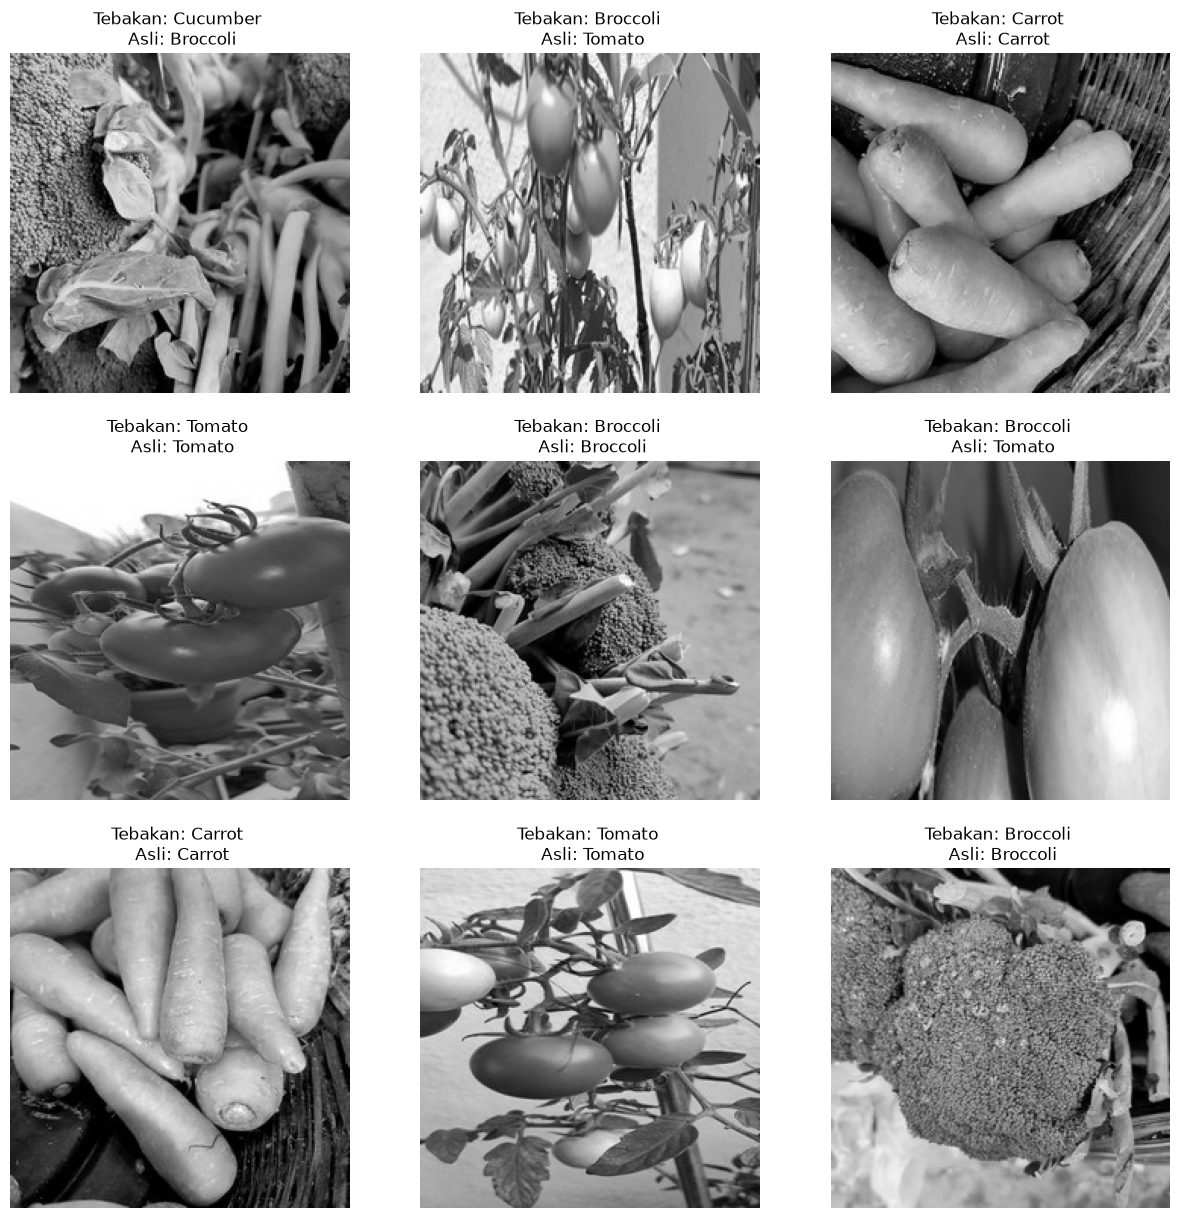

In [9]:
prediksi = model.predict(x_test)
tebakan = np.argmax(prediksi, axis=1)
real = np.argmax(y_test, axis=1)

plt.figure(figsize=(15,15))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Tebakan: {kelas[tebakan[i]]} \n Asli: {kelas[real[i]]}")
    plt.axis("off")
plt.show()


# 7. Evaluate

In [11]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Loss di data test:", loss)
print("Accuracy di data test:", accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 141ms/step - accuracy: 0.8500 - loss: 0.6270
Loss di data test: 0.6269903779029846
Accuracy di data test: 0.8500000238418579


# 8. Plotting Accuracy & Loss

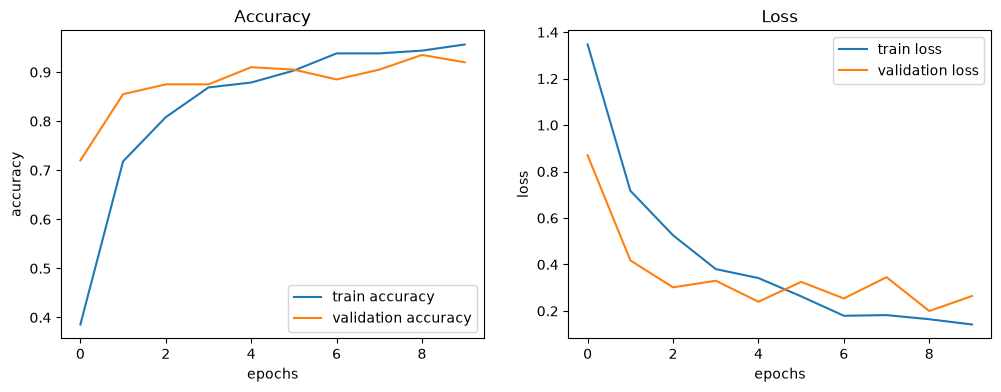

In [14]:
plt.figure(figsize=(12,4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label = "train accuracy")
plt.plot(history.history["val_accuracy"], label = "validation accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label = "train loss")
plt.plot(history.history["val_loss"], label = "validation loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("Loss")
plt.legend()

plt.show()